In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
folder = Path("data/brunt_ice_shelf")

with np.load(folder / "gcov_before.npz") as f:
    before = {k: f[k] for k in f.files}

with np.load(folder / "gcov_after.npz") as f:
    after = {k: f[k] for k in f.files}

print("Before layers:", list(before.keys()))
print("After layers:", list(after.keys()))

print("Before shape:", before["VVVV"].shape)
print("After shape:", after["VVVV"].shape)

Before layers: ['VVVV', 'x', 'y', 'epsg', 'pixel_m']
After layers: ['VVVV', 'x', 'y', 'epsg', 'pixel_m']
Before shape: (1707, 1562)
After shape: (1707, 1562)


In [3]:
print("Same shape:", before["VVVV"].shape == after["VVVV"].shape)

print("Same X coordinates:", np.array_equal(before["x"], after["x"]))
print("Same Y coordinates:", np.array_equal(before["y"], after["y"]))

print("Before EPSG:", before["epsg"])
print("After EPSG:", after["epsg"])

Same shape: True
Same X coordinates: True
Same Y coordinates: True
Before EPSG: 3031
After EPSG: 3031


In [4]:
before_db = 10 * np.log10(
    np.maximum(before["VVVV"].astype(float), 1e-10)
)

after_db = 10 * np.log10(
    np.maximum(after["VVVV"].astype(float), 1e-10)
)

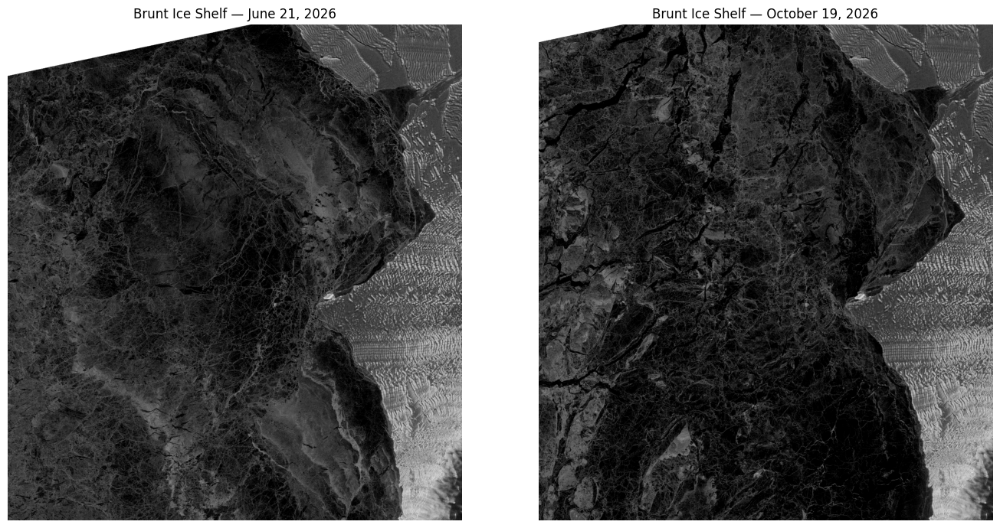

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].imshow(before_db, cmap="gray", vmin=-25, vmax=5)
axes[0].set_title("Brunt Ice Shelf — June 21, 2026")

axes[1].imshow(after_db, cmap="gray", vmin=-25, vmax=5)
axes[1].set_title("Brunt Ice Shelf — October 19, 2026")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

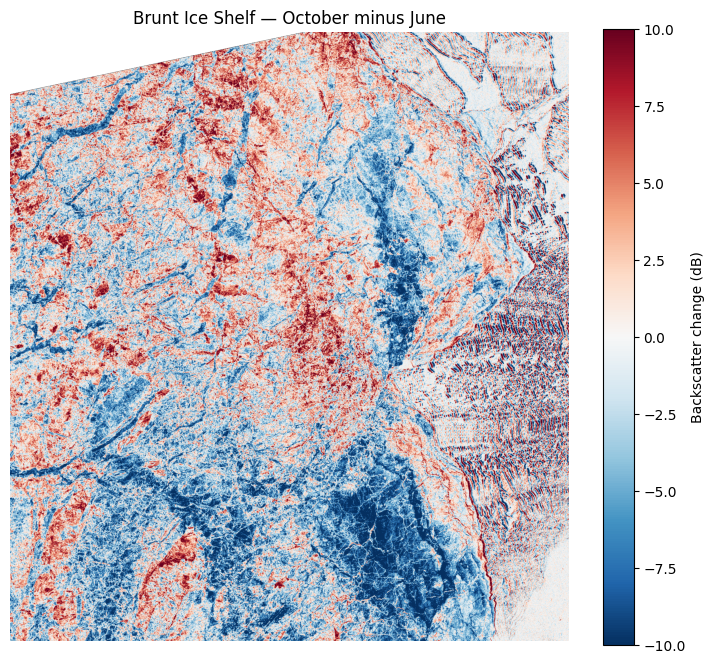

In [6]:
difference = after_db - before_db

plt.figure(figsize=(9, 8))

plt.imshow(
    difference,
    cmap="RdBu_r",
    vmin=-10,
    vmax=10
)

plt.colorbar(label="Backscatter change (dB)")
plt.title("Brunt Ice Shelf — October minus June")
plt.axis("off")
plt.show()

czoło

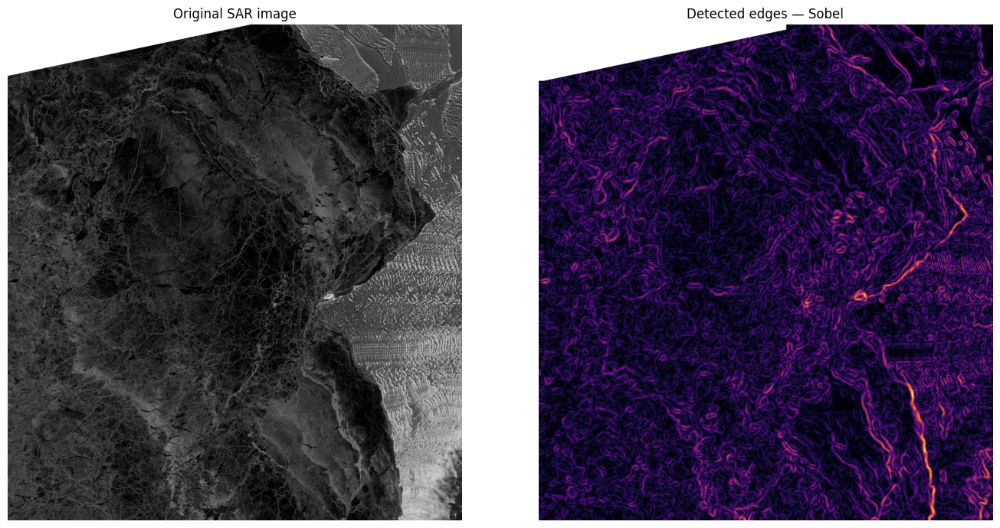

In [7]:
from scipy.ndimage import gaussian_filter, sobel

image = before_db.copy()

# Smooth the image to reduce SAR speckle
smoothed = gaussian_filter(image, sigma=4)

# Calculate gradients
grad_x = sobel(smoothed, axis=1)
grad_y = sobel(smoothed, axis=0)

gradient = np.hypot(grad_x, grad_y)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].imshow(image, cmap="gray", vmin=-25, vmax=5)
axes[0].set_title("Original SAR image")

axes[1].imshow(gradient, cmap="inferno")
axes[1].set_title("Detected edges — Sobel")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

Valid pixels: 97.22529135509654 %


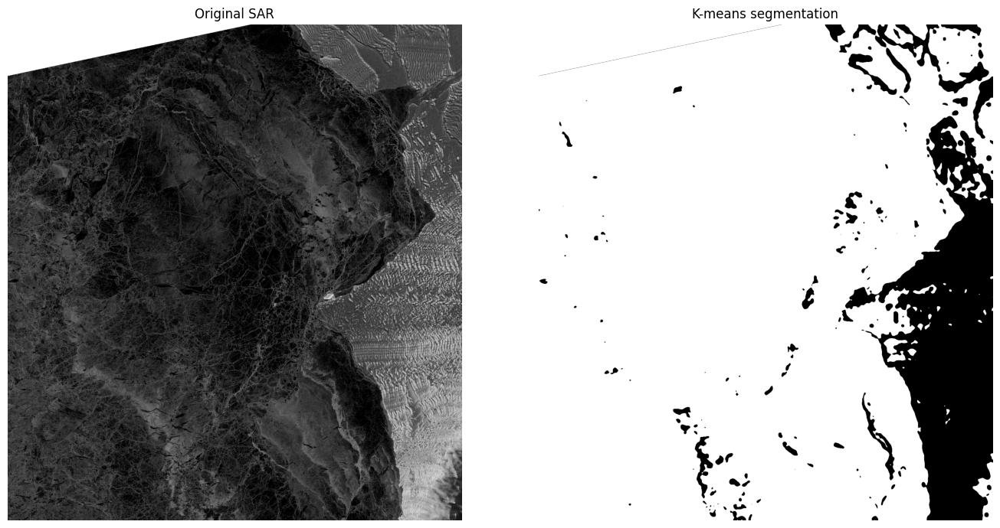

In [8]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from scipy.ndimage import gaussian_filter
import numpy as np
import matplotlib.pyplot as plt

# Identify valid pixels
valid_mask = np.isfinite(before_db)

print("Valid pixels:", valid_mask.mean() * 100, "%")

# Fill invalid pixels temporarily for filtering
filled = before_db.copy()
filled[~valid_mask] = np.nanmedian(before_db)

# Smooth the SAR image
smoothed = gaussian_filter(filled, sigma=8)

# Calculate local texture
local_mean = gaussian_filter(filled, sigma=5)
local_var = gaussian_filter(filled**2, sigma=5) - local_mean**2
local_std = np.sqrt(np.maximum(local_var, 0))

# Create features
features = np.stack([
    smoothed.ravel(),
    local_std.ravel()
], axis=1)

# Use only valid pixels
valid_features = features[valid_mask.ravel()]

# Normalize
scaler = StandardScaler()
valid_features = scaler.fit_transform(valid_features)

# K-means
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
valid_labels = kmeans.fit_predict(valid_features)

# Reconstruct image
labels = np.full(before_db.shape, np.nan)
labels[valid_mask] = valid_labels

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].imshow(before_db, cmap="gray", vmin=-25, vmax=5)
axes[0].set_title("Original SAR")

axes[1].imshow(labels, cmap="gray")
axes[1].set_title("K-means segmentation")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

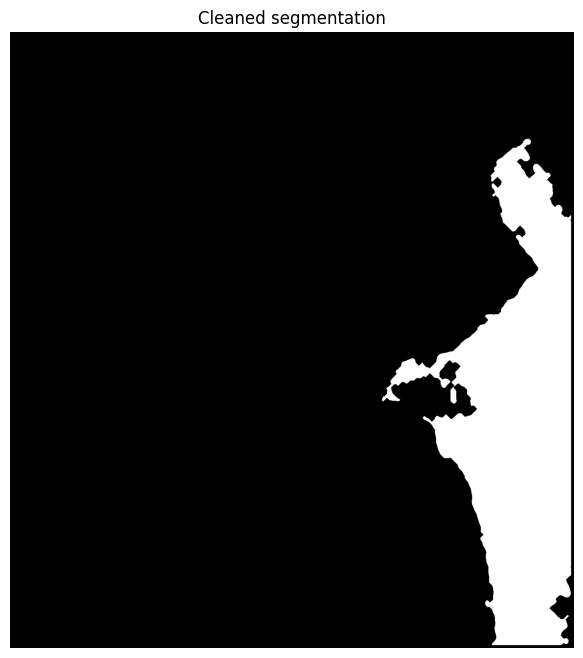

In [9]:
from scipy.ndimage import (
    binary_opening,
    binary_closing,
    binary_fill_holes,
    label
)

# Identify the cluster dominating the right edge
right_labels = labels[:, -100:]
right_labels = right_labels[np.isfinite(right_labels)]

right_cluster = int(np.bincount(right_labels.astype(int)).argmax())

# Create binary mask
mask = (labels == right_cluster)

# Remove small structures and connect nearby regions
mask = binary_opening(mask, iterations=3)
mask = binary_closing(mask, iterations=8)
mask = binary_fill_holes(mask)

# Keep the largest connected component
components, count = label(mask)

if count > 0:
    sizes = np.bincount(components.ravel())
    sizes[0] = 0
    mask = components == np.argmax(sizes)

plt.figure(figsize=(8, 8))
plt.imshow(mask, cmap="gray")
plt.title("Cleaned segmentation")
plt.axis("off")
plt.show()

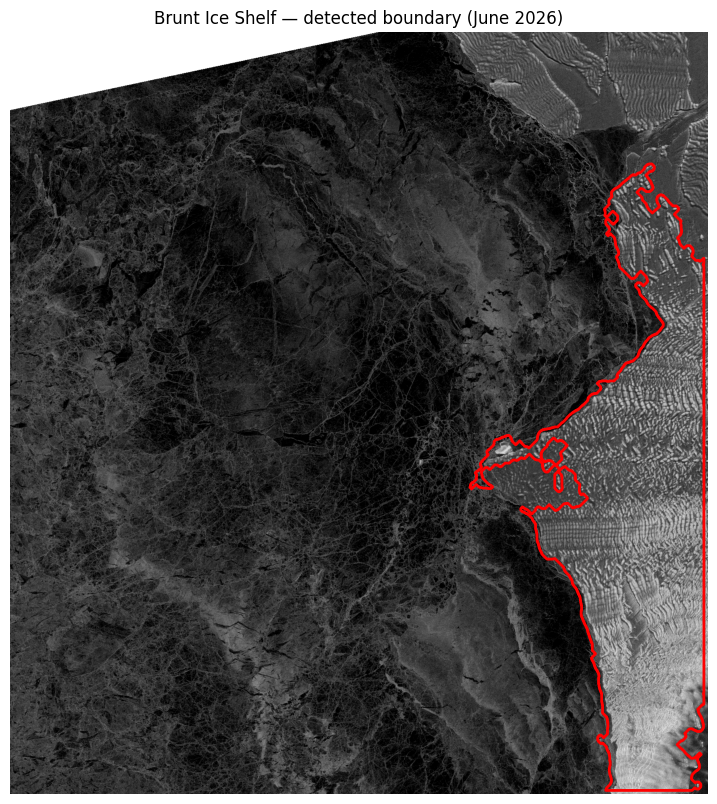

In [10]:
plt.figure(figsize=(9, 10))

plt.imshow(before_db, cmap="gray", vmin=-25, vmax=5)

plt.contour(
    mask.astype(float),
    levels=[0.5],
    colors="red",
    linewidths=2
)

plt.title("Brunt Ice Shelf — detected boundary (June 2026)")
plt.axis("off")
plt.show()

In [11]:
from pyproj import Transformer
import numpy as np

x = before["x"]
y = before["y"]
epsg = int(before["epsg"])

transformer = Transformer.from_crs(
    f"EPSG:{epsg}",
    "EPSG:4326",
    always_xy=True
)

# Check coordinates of a few locations along the boundary
points = [
    (int(len(y) * 0.25), int(len(x) * 0.85)),
    (int(len(y) * 0.50), int(len(x) * 0.75)),
    (int(len(y) * 0.75), int(len(x) * 0.85)),
]

for row, col in points:
    lon, lat = transformer.transform(
        float(x[col]),
        float(y[row])
    )
    print(f"Pixel ({row}, {col}): lon={lon:.4f}, lat={lat:.4f}")

Pixel (426, 1327): lon=-25.1008, lat=-75.1902
Pixel (853, 1171): lon=-26.0289, lat=-75.4206
Pixel (1280, 1327): lon=-26.1679, lat=-75.7484


In [12]:
from scipy.ndimage import binary_erosion
from pyproj import Transformer

edge = mask & ~binary_erosion(mask)

rows, cols = np.where(edge)

transformer = Transformer.from_crs(
    f"EPSG:{int(before['epsg'])}",
    "EPSG:4326",
    always_xy=True
)

# Sample points along the detected boundary
indices = np.linspace(0, len(rows) - 1, 10, dtype=int)

for i in indices:
    lon, lat = transformer.transform(
        float(before["x"][cols[i]]),
        float(before["y"][rows[i]])
    )
    print(f"lon={lon:.4f}, lat={lat:.4f}")

lon=-24.6818, lat=-75.1362
lon=-25.0849, lat=-75.1969
lon=-24.7482, lat=-75.3861
lon=-25.7095, lat=-75.4442
lon=-26.4264, lat=-75.4513
lon=-26.5877, lat=-75.4789
lon=-25.3733, lat=-75.7197
lon=-25.6726, lat=-75.8736
lon=-26.5964, lat=-75.9418
lon=-26.1825, lat=-76.0847


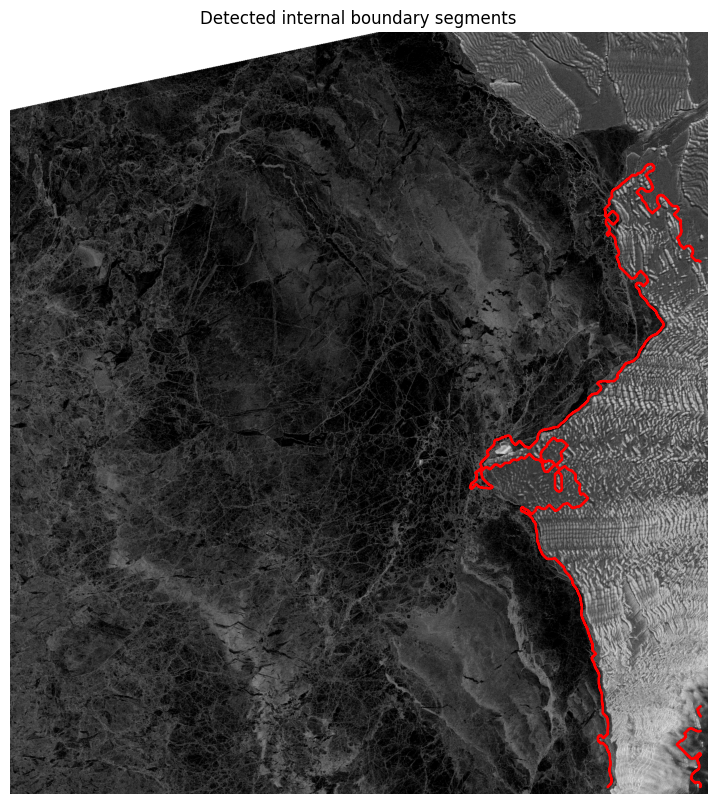

In [13]:
from scipy.ndimage import binary_erosion

edge = mask & ~binary_erosion(mask)

# Exclude image borders
margin = 15
edge[:margin, :] = False
edge[-margin:, :] = False
edge[:, :margin] = False
edge[:, -margin:] = False

plt.figure(figsize=(9, 10))
plt.imshow(before_db, cmap="gray", vmin=-25, vmax=5)
plt.contour(edge.astype(float), levels=[0.5], colors="red")
plt.title("Detected internal boundary segments")
plt.axis("off")
plt.show()

In [14]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from scipy.ndimage import (
    gaussian_filter,
    binary_opening,
    binary_closing,
    binary_fill_holes,
    label
)

def detect_ice_front(image_db):
    # Valid pixels
    valid_mask = np.isfinite(image_db)

    # Fill missing values for filtering
    filled = image_db.copy()
    filled[~valid_mask] = np.nanmedian(image_db)

    # Intensity and texture
    smoothed = gaussian_filter(filled, sigma=8)

    local_mean = gaussian_filter(filled, sigma=5)
    local_var = gaussian_filter(filled**2, sigma=5) - local_mean**2
    local_std = np.sqrt(np.maximum(local_var, 0))

    features = np.stack([
        smoothed.ravel(),
        local_std.ravel()
    ], axis=1)

    valid_features = features[valid_mask.ravel()]
    valid_features = StandardScaler().fit_transform(valid_features)

    # K-means
    kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
    valid_labels = kmeans.fit_predict(valid_features)

    labels = np.full(image_db.shape, np.nan)
    labels[valid_mask] = valid_labels

    # Identify the cluster on the right
    right_labels = labels[:, -100:]
    right_labels = right_labels[np.isfinite(right_labels)]

    right_cluster = int(
        np.bincount(right_labels.astype(int)).argmax()
    )

    mask = labels == right_cluster

    # Morphological cleaning
    mask = binary_opening(mask, iterations=3)
    mask = binary_closing(mask, iterations=8)
    mask = binary_fill_holes(mask)

    # Largest connected component
    components, count = label(mask)

    if count > 0:
        sizes = np.bincount(components.ravel())
        sizes[0] = 0
        mask = components == np.argmax(sizes)

    return mask

In [15]:
mask_before = detect_ice_front(before_db)
mask_after = detect_ice_front(after_db)

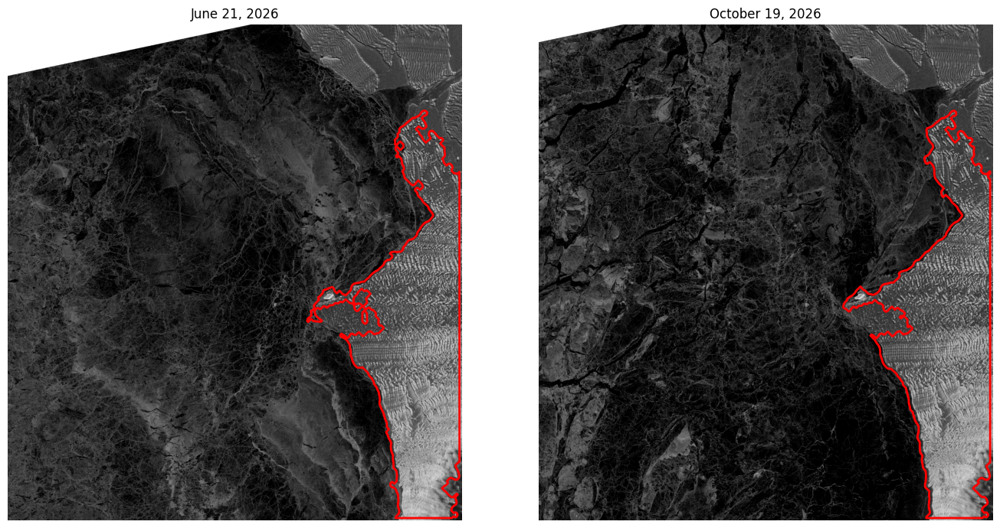

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

for ax, image, mask, title in zip(
    axes,
    [before_db, after_db],
    [mask_before, mask_after],
    ["June 21, 2026", "October 19, 2026"]
):
    ax.imshow(image, cmap="gray", vmin=-25, vmax=5)
    ax.contour(mask.astype(float), levels=[0.5],
               colors="red", linewidths=2)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [17]:
same_grid = (
    before_db.shape == after_db.shape
    and np.allclose(before["x"], after["x"], rtol=0, atol=1e-6)
    and np.allclose(before["y"], after["y"], rtol=0, atol=1e-6)
    and int(before["epsg"]) == int(after["epsg"])
)

print("Same grid:", same_grid)

Same grid: True


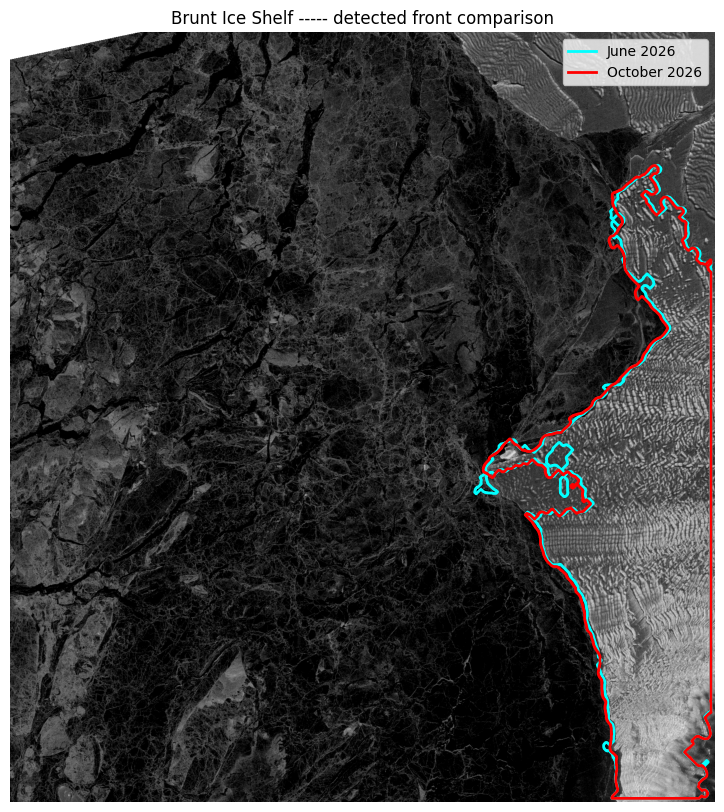

In [18]:
if not same_grid:
    raise ValueError("Rasters must be aligned before overlay.")

plt.figure(figsize=(10, 10))

plt.imshow(after_db, cmap="gray", vmin=-25, vmax=5)

plt.contour(
    mask_before.astype(float),
    levels=[0.5],
    colors="cyan",
    linewidths=2
)

plt.contour(
    mask_after.astype(float),
    levels=[0.5],
    colors="red",
    linewidths=2
)

from matplotlib.lines import Line2D

plt.legend(handles=[
    Line2D([0], [0], color="cyan", lw=2, label="June 2026"),
    Line2D([0], [0], color="red", lw=2, label="October 2026")
])

plt.title("Brunt Ice Shelf ----- detected front comparison")
plt.axis("off")
plt.show()

In [19]:
from scipy.ndimage import binary_erosion, distance_transform_edt
import numpy as np

# Extract boundaries
edge_before = mask_before & ~binary_erosion(mask_before)
edge_after = mask_after & ~binary_erosion(mask_after)

# Exclude image borders
margin = 15

for edge in (edge_before, edge_after):
    edge[:margin, :] = False
    edge[-margin:, :] = False
    edge[:, :margin] = False
    edge[:, -margin:] = False

# Pixel spacing in meters (assuming projected CRS in meters)
dx = abs(np.median(np.diff(before["x"])))
dy = abs(np.median(np.diff(before["y"])))

print(f"Pixel spacing: {dx:.2f} m × {dy:.2f} m")

# Distance to the nearest pixel on October boundary
dist_to_after = distance_transform_edt(
    ~edge_after,
    sampling=(dy, dx)
)

distances = dist_to_after[edge_before]

print(f"Mean displacement: {distances.mean():.2f} m")
print(f"Median displacement: {np.median(distances):.2f} m")
print(f"Maximum displacement: {distances.max():.2f} m")

Pixel spacing: 80.00 m × 80.00 m
Mean displacement: 531.10 m
Median displacement: 329.85 m
Maximum displacement: 3974.32 m


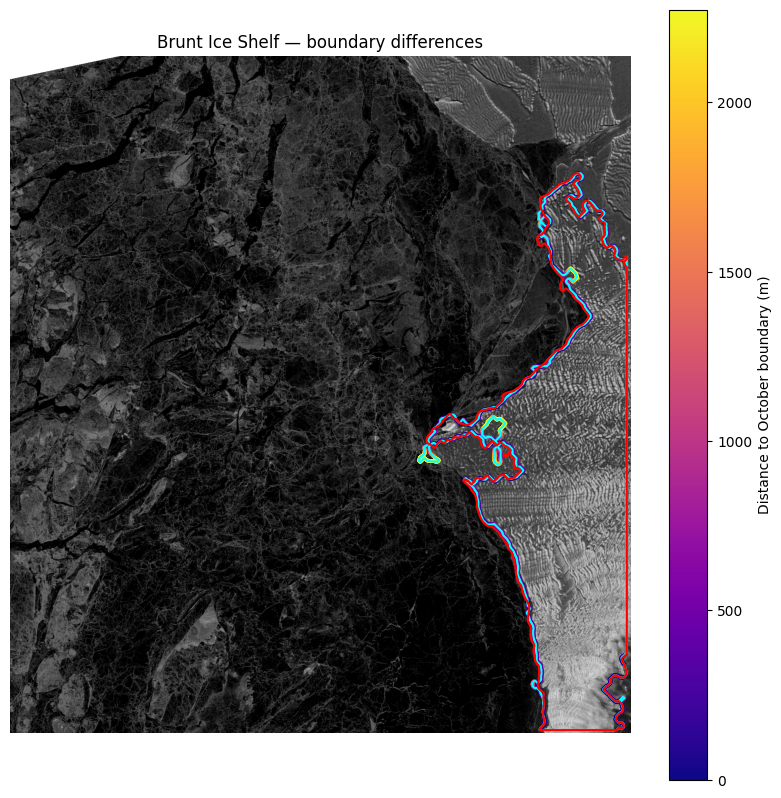

In [20]:
plt.figure(figsize=(10, 10))

plt.imshow(after_db, cmap="gray", vmin=-25, vmax=5)

plt.contour(
    mask_before.astype(float),
    levels=[0.5],
    colors="cyan",
    linewidths=1.5
)

plt.contour(
    mask_after.astype(float),
    levels=[0.5],
    colors="red",
    linewidths=1.5
)

# Color June boundary points by distance to October boundary
rows, cols = np.where(edge_before)

sc = plt.scatter(
    cols,
    rows,
    c=distances,
    cmap="plasma",
    s=3,
    vmin=0,
    vmax=np.percentile(distances, 95)
)

plt.colorbar(sc, label="Distance to October boundary (m)")
plt.title("Brunt Ice Shelf — boundary differences")
plt.axis("off")
plt.show()

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.ndimage import gaussian_filter

DATA_DIR = Path("data/brunt_ice_shelf")

In [22]:
def load_gcov(path, polarization="VVVV"):
    with np.load(path) as f:
        data = {key: f[key] for key in f.files}

    image = data[polarization].astype(np.float32)

    valid = np.isfinite(image) & (image > 0)

    image_db = np.full(image.shape, np.nan, dtype=np.float32)
    image_db[valid] = 10 * np.log10(image[valid])

    return image_db, valid, data


before_db, valid_before, before = load_gcov(
    DATA_DIR / "gcov_before.npz"
)

after_db, valid_after, after = load_gcov(
    DATA_DIR / "gcov_after.npz"
)

print("Before:", before_db.shape)
print("After:", after_db.shape)
print("Valid before:", f"{valid_before.mean():.2%}")
print("Valid after:", f"{valid_after.mean():.2%}")

Before: (1707, 1562)
After: (1707, 1562)
Valid before: 97.23%
Valid after: 99.67%


In [23]:
same_grid = (
    before_db.shape == after_db.shape
    and np.array_equal(before["x"], after["x"])
    and np.array_equal(before["y"], after["y"])
    and int(before["epsg"]) == int(after["epsg"])
)

print("Same grid:", same_grid)
print("EPSG:", before["epsg"])

if not same_grid:
    raise ValueError("Images need to be aligned before change detection.")

Same grid: True
EPSG: 3031


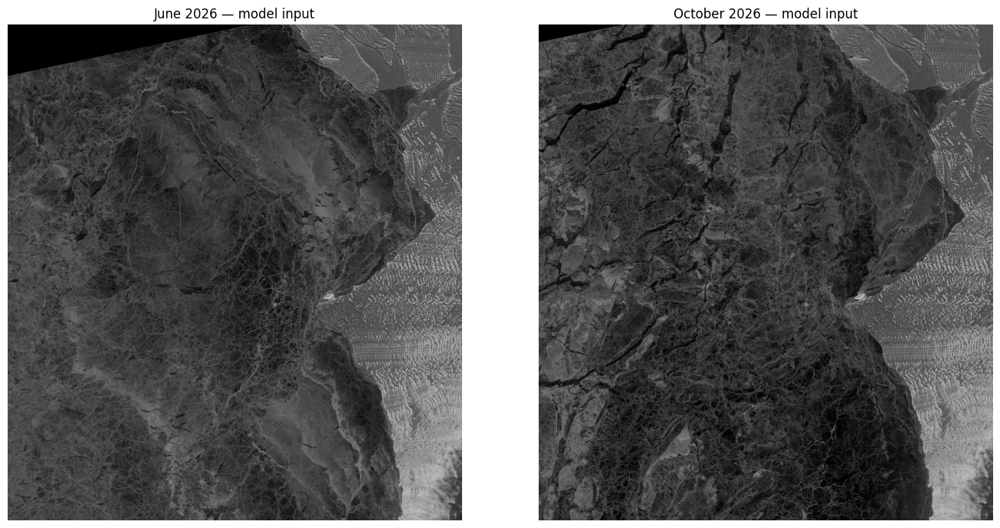

In [24]:
def preprocess_sar(image_db, valid_mask):
    # Clip extreme backscatter values
    clipped = np.clip(image_db, -30, 10)

    # Normalize to [0, 1]
    normalized = (clipped + 30) / 40

    # Invalid pixels should not contribute to the model
    normalized[~valid_mask] = 0

    return normalized.astype(np.float32)


before_input = preprocess_sar(before_db, valid_before)
after_input = preprocess_sar(after_db, valid_after)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].imshow(before_input, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("June 2026 — model input")

axes[1].imshow(after_input, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("October 2026 — model input")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [25]:
def extract_patches(image, valid_mask, patch_size=256, stride=256):
    patches = []
    positions = []

    height, width = image.shape

    for row in range(0, height - patch_size + 1, stride):
        for col in range(0, width - patch_size + 1, stride):

            patch = image[
                row:row + patch_size,
                col:col + patch_size
            ]

            valid_patch = valid_mask[
                row:row + patch_size,
                col:col + patch_size
            ]

            # Keep patches with at least 90% valid pixels
            if valid_patch.mean() < 0.9:
                continue

            patches.append(patch)
            positions.append((row, col))

    return np.stack(patches), positions


patches_before, positions_before = extract_patches(
    before_input, valid_before
)

patches_after, positions_after = extract_patches(
    after_input, valid_after
)

print("Before patches:", patches_before.shape)
print("After patches:", patches_after.shape)

Before patches: (33, 256, 256)
After patches: (35, 256, 256)


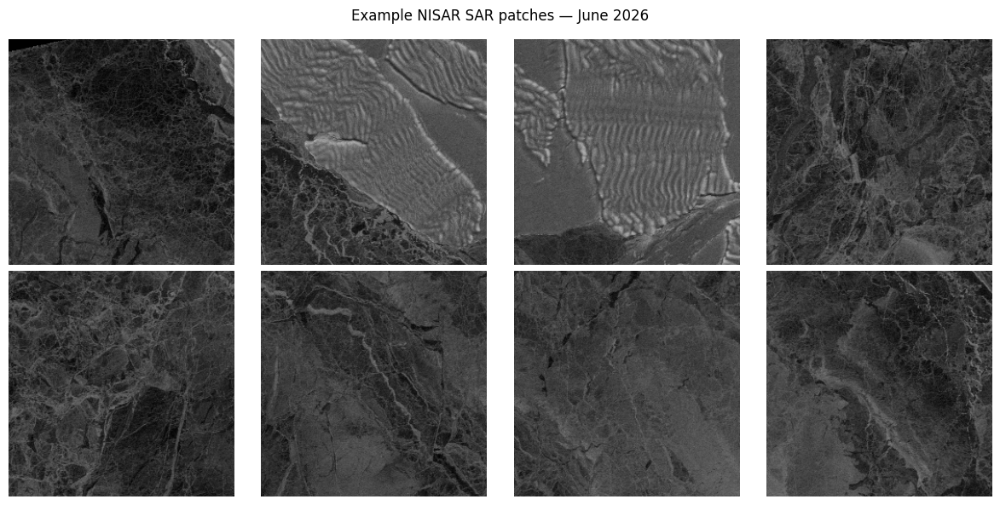

In [26]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    if i < len(patches_before):
        ax.imshow(patches_before[i], cmap="gray", vmin=0, vmax=1)
    ax.axis("off")

plt.suptitle("Example NISAR SAR patches — June 2026")
plt.tight_layout()
plt.show()

In [27]:
from scipy.ndimage import binary_erosion

# If mask_before exists in your notebook
front_edge = mask_before & ~binary_erosion(mask_before)

front_patches = []

for i, (row, col) in enumerate(positions_before):
    edge_patch = front_edge[
        row:row + 256,
        col:col + 256
    ]

    if edge_patch.any():
        front_patches.append(i)

print("Total patches:", len(patches_before))
print("Patches containing detected boundary:", len(front_patches))
print("Indices:", front_patches)

Total patches: 33
Patches containing detected boundary: 8
Indices: [8, 14, 19, 20, 25, 26, 31, 32]


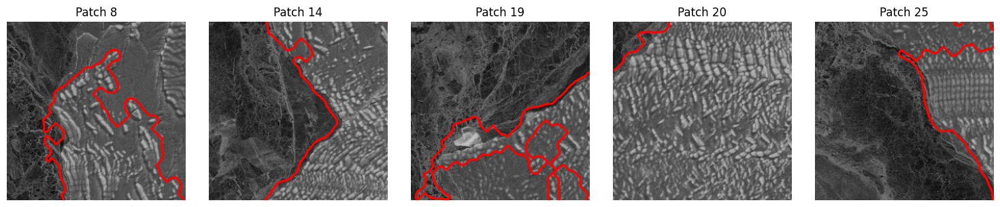

In [28]:
n = len(front_patches)

if n == 0:
    print("No patches contain the detected boundary.")
else:
    fig, axes = plt.subplots(
        1, min(n, 5),
        figsize=(3 * min(n, 5), 3),
        squeeze=False
    )

    for ax, idx in zip(axes.flat, front_patches[:5]):
        row, col = positions_before[idx]

        ax.imshow(patches_before[idx], cmap="gray", vmin=0, vmax=1)

        ax.contour(
            front_edge[row:row+256, col:col+256],
            levels=[0.5],
            colors="red"
        )

        ax.set_title(f"Patch {idx}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()

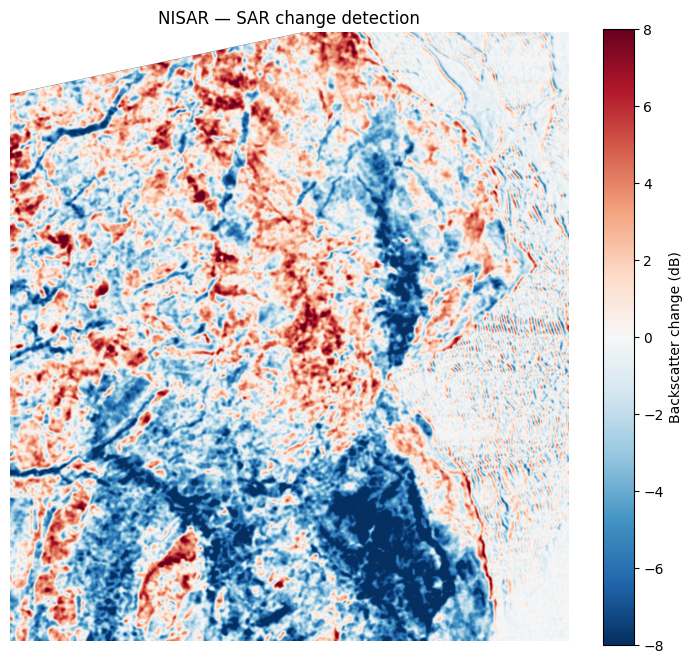

In [29]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

valid = np.isfinite(before_db) & np.isfinite(after_db)

def smooth_valid(image, valid, sigma=3):
    values = np.where(valid, image, 0.0)

    numerator = gaussian_filter(values, sigma=sigma)
    denominator = gaussian_filter(valid.astype(float), sigma=sigma)

    return numerator / np.maximum(denominator, 1e-8)

before_smooth = smooth_valid(before_db, valid)
after_smooth = smooth_valid(after_db, valid)

difference = after_smooth - before_smooth
difference[~valid] = np.nan

plt.figure(figsize=(9, 8))
plt.imshow(difference, cmap="RdBu_r", vmin=-8, vmax=8)
plt.colorbar(label="Backscatter change (dB)")
plt.title("NISAR — SAR change detection")
plt.axis("off")
plt.show()

Change threshold: 6.11 dB


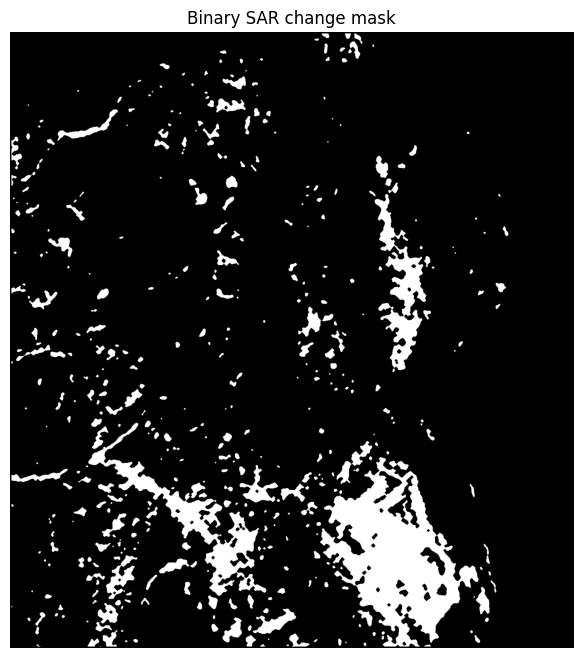

In [30]:
from scipy.ndimage import (
    binary_opening,
    binary_closing,
    label
)

absolute_difference = np.abs(difference)

threshold = np.nanpercentile(
    absolute_difference[valid], 90
)

change_mask = (
    (absolute_difference > threshold) & valid
)

change_mask = binary_opening(change_mask, iterations=2)
change_mask = binary_closing(change_mask, iterations=4)

print(f"Change threshold: {threshold:.2f} dB")

plt.figure(figsize=(9, 8))
plt.imshow(change_mask, cmap="gray")
plt.title("Binary SAR change mask")
plt.axis("off")
plt.show()

/var/folders/8x/ggv79f253c7fydy8xqpd8qrm0000gn/T/ipykernel_40360/2863764777.py:11: FutureWarning: `RegionProperties.minor_axis_length` is deprecated starting in version 0.26 and will be removed in version 2.0. Use `RegionProperties.axis_minor_length` instead. 
  if region.minor_axis_length <= 0:
/var/folders/8x/ggv79f253c7fydy8xqpd8qrm0000gn/T/ipykernel_40360/2863764777.py:15: FutureWarning: `RegionProperties.major_axis_length` is deprecated starting in version 0.26 and will be removed in version 2.0. Use `RegionProperties.axis_major_length` instead. 
  region.major_axis_length /
/var/folders/8x/ggv79f253c7fydy8xqpd8qrm0000gn/T/ipykernel_40360/2863764777.py:16: FutureWarning: `RegionProperties.minor_axis_length` is deprecated starting in version 0.26 and will be removed in version 2.0. Use `RegionProperties.axis_minor_length` instead. 
  region.minor_axis_length


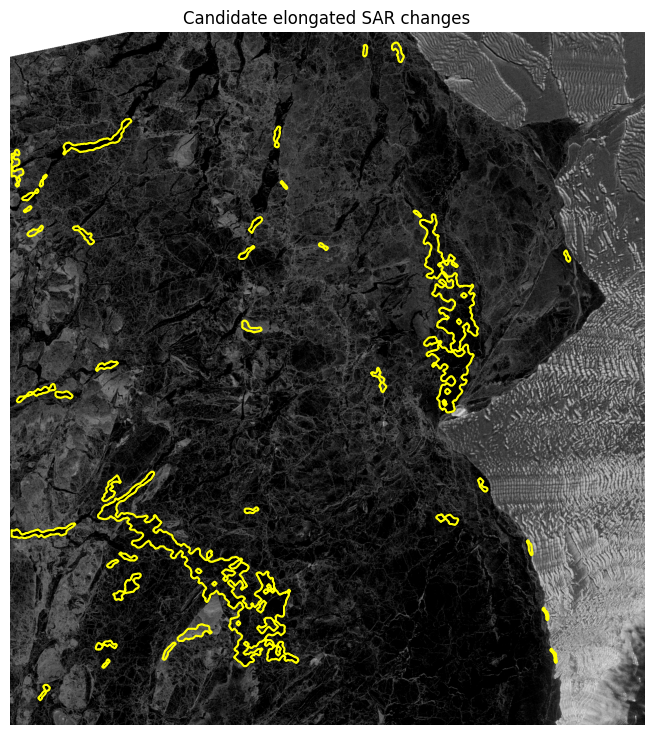

In [31]:
from skimage.measure import regionprops

components, count = label(change_mask)

long_changes = np.zeros_like(change_mask, dtype=bool)

for region in regionprops(components):
    if region.area < 100:
        continue

    if region.minor_axis_length <= 0:
        continue

    elongation = (
        region.major_axis_length /
        region.minor_axis_length
    )

    if elongation > 3:
        long_changes[components == region.label] = True

plt.figure(figsize=(10, 9))

plt.imshow(after_db, cmap="gray", vmin=-25, vmax=5)

plt.contour(
    long_changes.astype(float),
    levels=[0.5],
    colors="yellow",
    linewidths=1.5
)

plt.title("Candidate elongated SAR changes")
plt.axis("off")
plt.show()

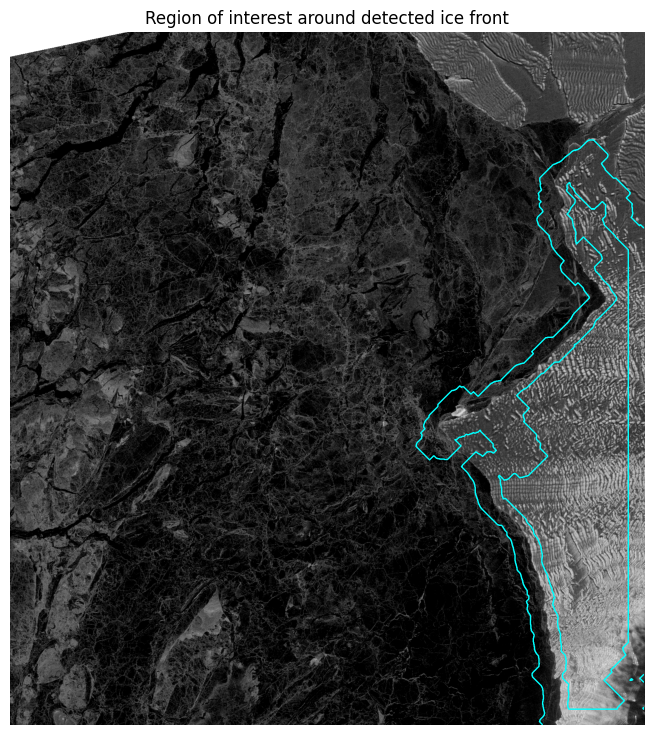

In [32]:
from scipy.ndimage import binary_dilation, binary_erosion
import numpy as np
import matplotlib.pyplot as plt

edge_before = mask_before & ~binary_erosion(mask_before)
edge_after = mask_after & ~binary_erosion(mask_after)

# Region around both detected boundaries
front_region = binary_dilation(
    edge_before | edge_after,
    iterations=30
)

front_region &= valid

plt.figure(figsize=(10, 9))
plt.imshow(after_db, cmap="gray", vmin=-25, vmax=5)

plt.contour(
    front_region.astype(float),
    levels=[0.5],
    colors="cyan",
    linewidths=1
)

plt.title("Region of interest around detected ice front")
plt.axis("off")
plt.show()

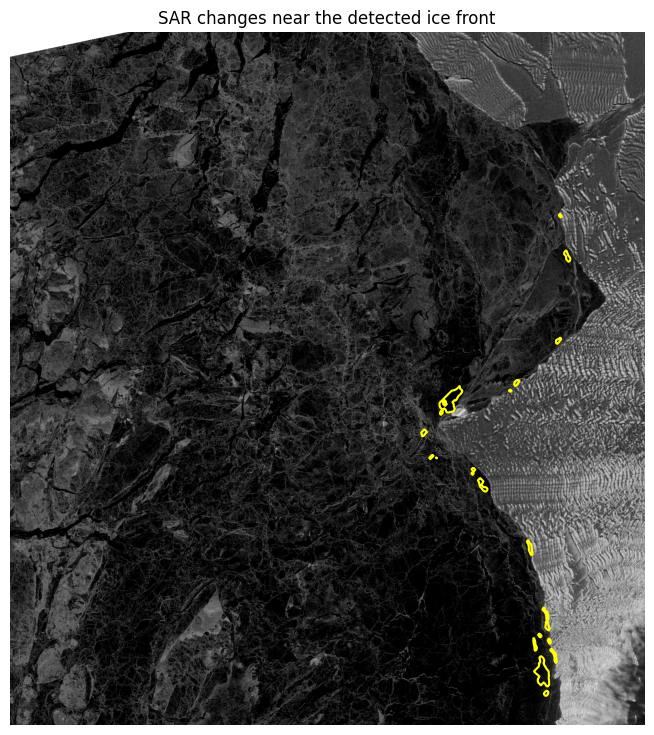

In [33]:
# Changes within the front region
front_changes = change_mask & front_region

plt.figure(figsize=(10, 9))
plt.imshow(after_db, cmap="gray", vmin=-25, vmax=5)

plt.contour(
    front_changes.astype(float),
    levels=[0.5],
    colors="yellow",
    linewidths=1.5
)

plt.title("SAR changes near the detected ice front")
plt.axis("off")
plt.show()

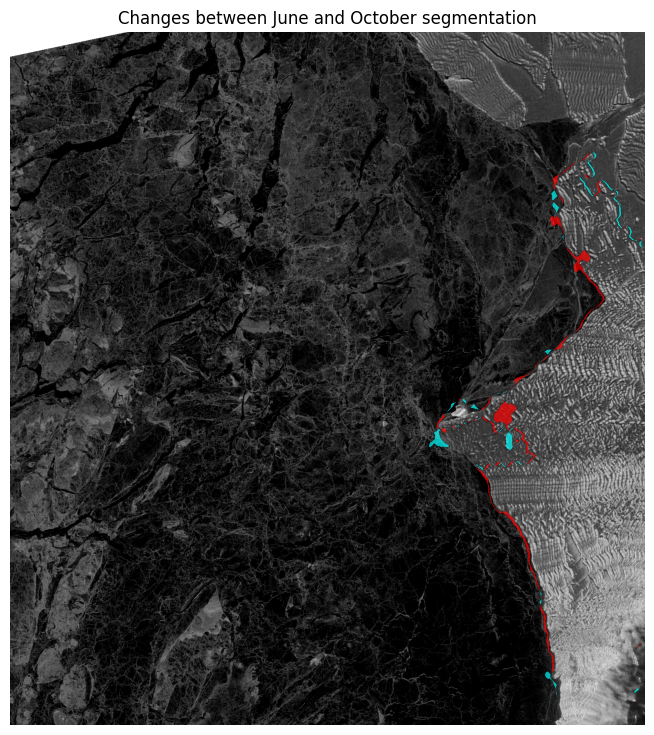

In [34]:
# Pixels whose classification changed
changed_to_right = (~mask_before) & mask_after & valid
changed_from_right = mask_before & (~mask_after) & valid

plt.figure(figsize=(10, 9))
plt.imshow(after_db, cmap="gray", vmin=-25, vmax=5)

overlay = np.zeros((*after_db.shape, 4), dtype=float)

# Red: changed to the right-side class
overlay[changed_to_right] = [1, 0, 0, 0.7]

# Cyan: changed from the right-side class
overlay[changed_from_right] = [0, 1, 1, 0.7]

plt.imshow(overlay)

plt.title("Changes between June and October segmentation")
plt.axis("off")
plt.show()

In [35]:
import numpy as np

# Pixel dimensions
dx = abs(np.median(np.diff(before["x"])))
dy = abs(np.median(np.diff(before["y"])))

print(f"Pixel size: {dx:.2f} × {dy:.2f} CRS units")
print("EPSG:", before["epsg"])

# Check that the CRS uses metres
from pyproj import CRS

crs = CRS.from_epsg(int(before["epsg"]))
assert crs.is_projected
assert all(axis.unit_name.lower() in ("metre", "meter")
           for axis in crs.axis_info[:2])

pixel_area_km2 = dx * dy / 1e6

# Calculate changes only where both images are valid
common_valid = valid_before & valid_after

potential_loss = (~mask_before) & mask_after & common_valid
potential_gain = mask_before & (~mask_after) & common_valid

loss_km2 = potential_loss.sum() * pixel_area_km2
gain_km2 = potential_gain.sum() * pixel_area_km2

print(f"Potential ice area loss: {loss_km2:.3f} km²")
print(f"Potential ice area gain: {gain_km2:.3f} km²")
print(f"Net classified ice area change: {gain_km2 - loss_km2:.3f} km²")

Pixel size: 80.00 × 80.00 CRS units
EPSG: 3031
Potential ice area loss: 72.563 km²
Potential ice area gain: 31.603 km²
Net classified ice area change: -40.960 km²


In [36]:
import asf_search as asf

# Use the exact scene names from the current pair
before_scene = "NISAR_L2_PR_GCOV_023_109_D_126_0005_NASV_A_20260621T190035_20260621T190112_P05023_N_F_J_001"
after_scene = "NISAR_L2_PR_GCOV_033_109_D_126_0005_NASV_A_20261019T190035_20261019T190112_P05023_N_F_J_001"

# Search the existing Brunt Ice Shelf area
bbox = [-28.5, -75.8, -25.5, -74.8]
w, s, e, n = bbox

wkt = (
    f"POLYGON(({w} {s},{e} {s},"
    f"{e} {n},{w} {n},{w} {s}))"
)

results = asf.search(
    platform=["NISAR"],
    processingLevel=["GCOV"],
    intersectsWith=wkt,
    start="2026-08-01",
    end="2026-10-01",
    maxResults=250
)

# Same track, frame and acquisition mode
matching = []

for item in results:
    scene = item.properties.get("sceneName", "")

    if "_109_D_126_" in scene and "_NASV_" in scene:
        matching.append(item)

print(f"Found {len(matching)} matching products")

for item in matching:
    print(
        item.properties.get("startTime"),
        item.properties.get("sceneName")
    )

Found 4 matching products
2026-09-25T19:00:35Z NISAR_L2_PR_GCOV_031_109_D_126_0005_NASV_A_20260925T190035_20260925T190111_P05023_N_F_J_001
2026-09-13T19:00:35Z NISAR_L2_PR_GCOV_030_109_D_126_0005_NASV_A_20260913T190035_20260913T190111_P05023_N_F_J_001
2026-09-01T19:00:35Z NISAR_L2_PR_GCOV_029_109_D_126_0005_NASV_A_20260901T190035_20260901T190112_P05023_N_F_J_001
2026-08-20T19:00:35Z NISAR_L2_PR_GCOV_028_109_D_126_0005_NASV_A_20260820T190035_20260820T190112_P05023_N_F_J_001


In [37]:
middle_db, valid_middle, middle = load_gcov(
    DATA_DIR / "gcov_middle.npz"
)

print("Middle shape:", middle_db.shape)
print("Middle EPSG:", middle["epsg"])

same_grid = (
    before_db.shape == middle_db.shape == after_db.shape
    and np.array_equal(before["x"], middle["x"])
    and np.array_equal(before["y"], middle["y"])
    and np.array_equal(middle["x"], after["x"])
    and np.array_equal(middle["y"], after["y"])
    and int(before["epsg"]) == int(middle["epsg"]) == int(after["epsg"])
)

print("All three images aligned:", same_grid)

Middle shape: (1707, 1562)
Middle EPSG: 3031
All three images aligned: True


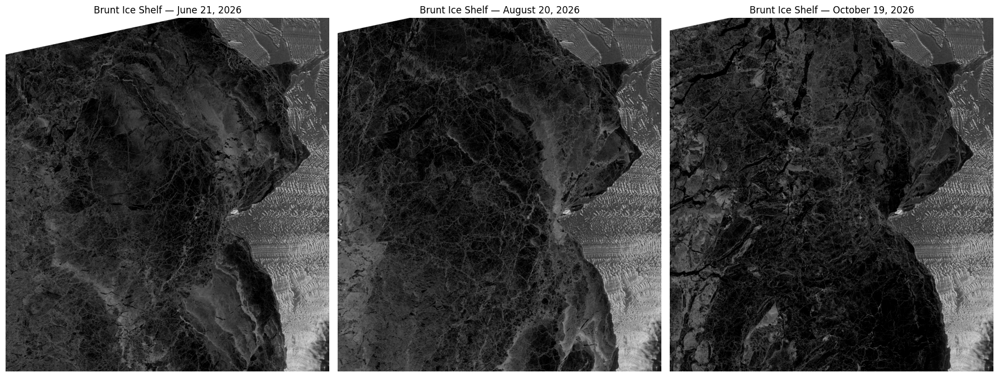

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(18, 7))

images = [before_db, middle_db, after_db]
dates = ["June 21", "August 20", "October 19"]

for ax, image, date in zip(axes, images, dates):
    ax.imshow(image, cmap="gray", vmin=-25, vmax=5)
    ax.set_title(f"Brunt Ice Shelf — {date}, 2026")
    ax.axis("off")

plt.tight_layout()
plt.show()

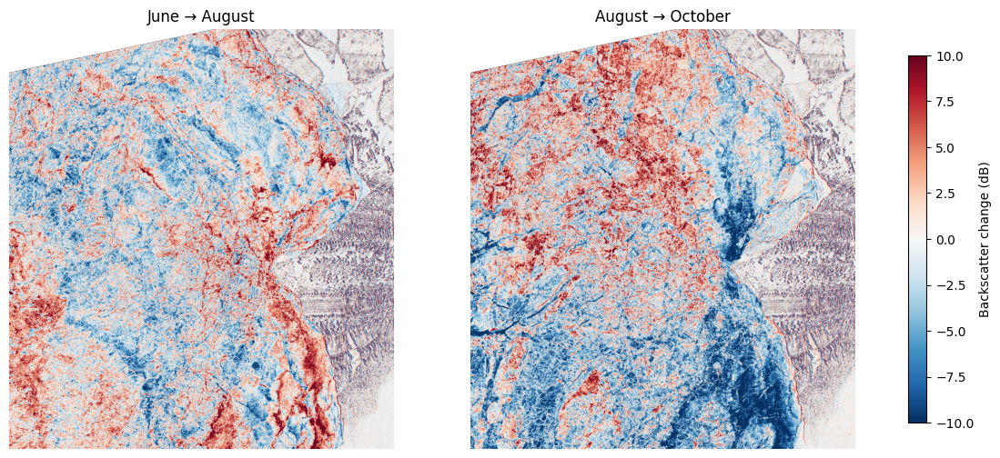

In [39]:
common_valid = valid_before & valid_middle & valid_after

diff_jun_aug = middle_db - before_db
diff_aug_oct = after_db - middle_db

diff_jun_aug[~common_valid] = np.nan
diff_aug_oct[~common_valid] = np.nan

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

for ax, diff, title in zip(
    axes,
    [diff_jun_aug, diff_aug_oct],
    ["June → August", "August → October"]
):
    im = ax.imshow(diff, cmap="RdBu_r", vmin=-10, vmax=10)
    ax.set_title(title)
    ax.axis("off")

fig.colorbar(
    im,
    ax=axes,
    label="Backscatter change (dB)",
    shrink=0.75
)

plt.show()

In [40]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from scipy.ndimage import gaussian_filter
import numpy as np

def extract_features(image):
    valid = np.isfinite(image)
    filled = np.where(valid, image, -25.0)

    smoothed = gaussian_filter(filled, sigma=8)
    local_mean = gaussian_filter(filled, sigma=5)
    local_var = gaussian_filter(filled**2, sigma=5) - local_mean**2
    local_std = np.sqrt(np.maximum(local_var, 0))

    return np.stack([smoothed, local_std], axis=-1)


images = [before_db, middle_db, after_db]
features_list = [extract_features(img) for img in images]

# Use pixels valid in all three acquisitions
common_valid = valid_before & valid_middle & valid_after

rng = np.random.default_rng(42)
samples = []

for features in features_list:
    pixels = features[common_valid]
    idx = rng.choice(
        len(pixels),
        size=min(50000, len(pixels)),
        replace=False
    )
    samples.append(pixels[idx])

train_features = np.concatenate(samples)

scaler = StandardScaler()
train_scaled = scaler.fit_transform(train_features)

kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans.fit(train_scaled)

print("Cluster centers:", scaler.inverse_transform(kmeans.cluster_centers_))

Cluster centers: [[-20.667114    2.3403475]
 [-12.975659    3.7320216]]


In [41]:
from scipy.ndimage import (
    binary_opening,
    binary_closing,
    binary_fill_holes,
    label
)

def segment_image(features, valid):
    h, w, _ = features.shape

    labels = kmeans.predict(
        scaler.transform(features.reshape(-1, 2))
    ).reshape(h, w)

    # Choose the cluster dominating the right edge
    right_pixels = labels[:, -100:][valid[:, -100:]]
    right_class = np.bincount(right_pixels, minlength=2).argmax()

    mask = (labels == right_class) & valid

    mask = binary_opening(mask, iterations=3)
    mask = binary_closing(mask, iterations=8)

    components, count = label(mask)

    if count > 0:
        sizes = np.bincount(components.ravel())
        sizes[0] = 0
        mask = components == sizes.argmax()

    mask = binary_fill_holes(mask)

    return mask


masks = [
    segment_image(features, valid)
    for features, valid in zip(
        features_list,
        [valid_before, valid_middle, valid_after]
    )
]

mask_june, mask_august, mask_october = masks

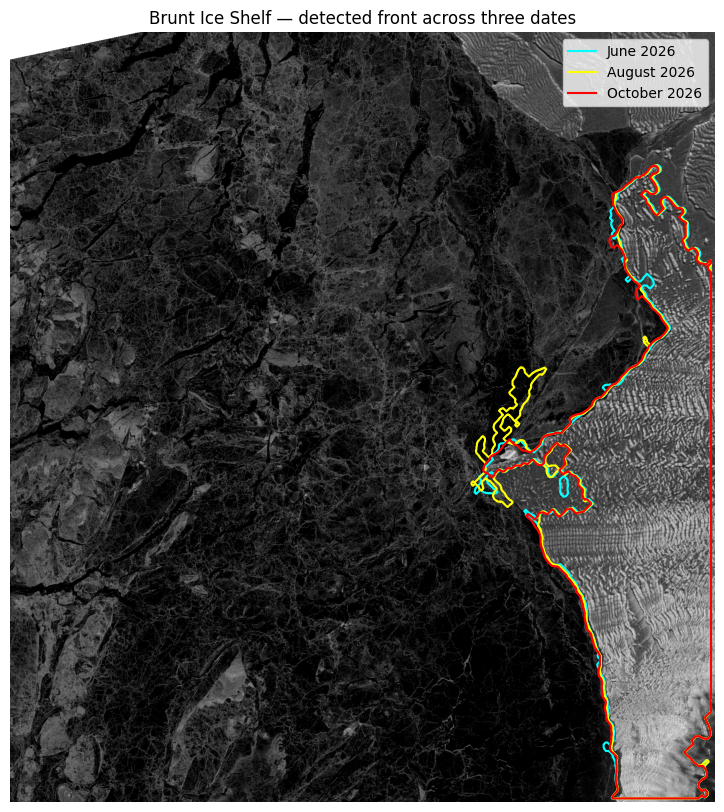

In [42]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 10))

plt.imshow(after_db, cmap="gray", vmin=-25, vmax=5)

for mask, color, name in zip(
    masks,
    ["cyan", "yellow", "red"],
    ["June 2026", "August 2026", "October 2026"]
):
    plt.contour(
        mask.astype(float),
        levels=[0.5],
        colors=color,
        linewidths=1.5
    )

    plt.plot([], [], color=color, label=name)

plt.legend()
plt.title("Brunt Ice Shelf — detected front across three dates")
plt.axis("off")
plt.show()

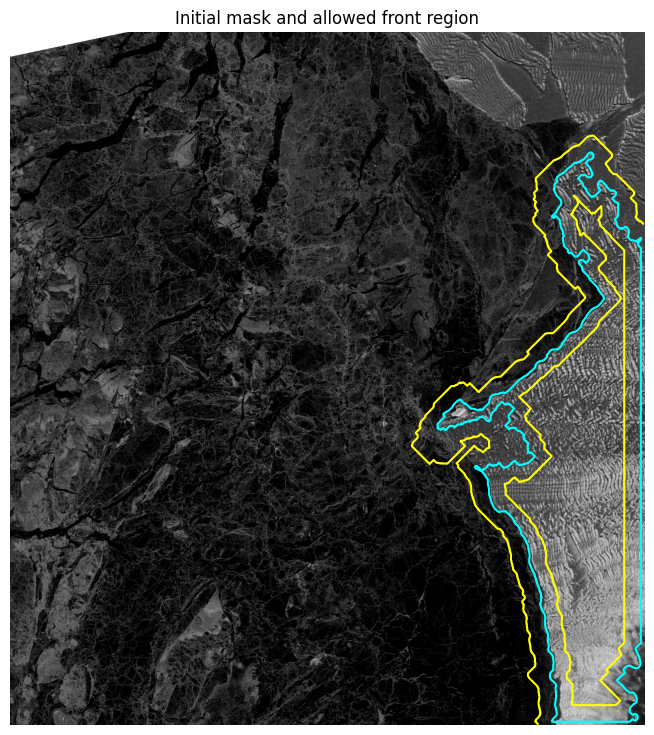

In [43]:
from scipy.ndimage import (
    gaussian_filter,
    binary_dilation,
    binary_erosion
)
from skimage.segmentation import morphological_chan_vese
import numpy as np
import matplotlib.pyplot as plt

# Common initial segmentation
initial_mask = (
    mask_june.astype(bool) &
    mask_october.astype(bool)
)

# Allow movement around either detected boundary
front_band = binary_dilation(
    mask_june ^ mask_october,
    iterations=40
)

# Include a neighborhood around the initial front
initial_edge = initial_mask ^ binary_erosion(initial_mask)

front_band |= binary_dilation(
    initial_edge,
    iterations=40
)

plt.figure(figsize=(9, 9))
plt.imshow(after_db, cmap="gray", vmin=-25, vmax=5)
plt.contour(initial_mask, levels=[0.5], colors="cyan")
plt.contour(front_band, levels=[0.5], colors="yellow")
plt.title("Initial mask and allowed front region")
plt.axis("off")
plt.show()

In [44]:
def detect_front_active_contour(image_db, initial_mask, iterations=80):
    valid = np.isfinite(image_db)

    # Replace invalid values before filtering
    filled = np.where(valid, image_db, -25)

    # Normalize radar intensity
    normalized = np.clip((filled + 30) / 40, 0, 1)

    # Reduce speckle
    smoothed = gaussian_filter(normalized, sigma=3)

    # Morphological Chan-Vese
    result = morphological_chan_vese(
        smoothed,
        num_iter=iterations,
        init_level_set=initial_mask,
        smoothing=2
    )

    return result & valid


active_masks = [
    detect_front_active_contour(img, initial_mask)
    for img in [before_db, middle_db, after_db]
]

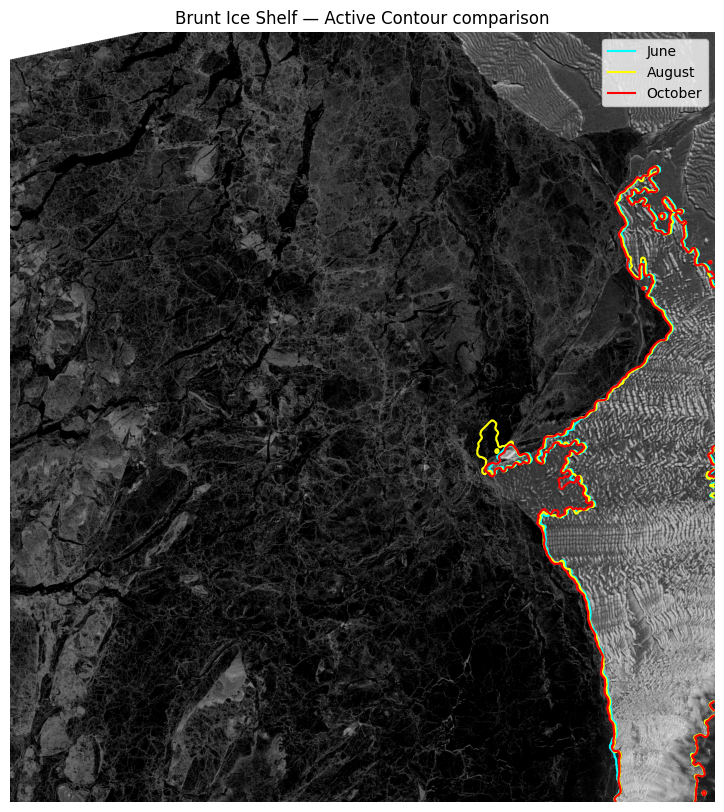

In [45]:
plt.figure(figsize=(11, 10))

plt.imshow(after_db, cmap="gray", vmin=-25, vmax=5)

for mask, color, date in zip(
    active_masks,
    ["cyan", "yellow", "red"],
    ["June", "August", "October"]
):
    plt.contour(
        mask.astype(float),
        levels=[0.5],
        colors=color,
        linewidths=1.5
    )
    plt.plot([], [], color=color, label=date)

plt.legend()
plt.title("Brunt Ice Shelf — Active Contour comparison")
plt.axis("off")
plt.show()

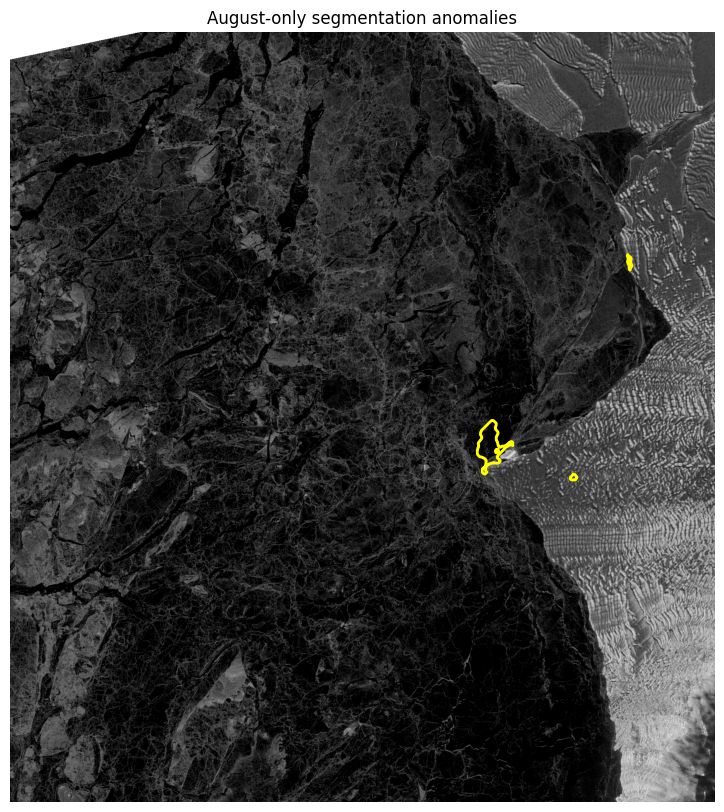

In [46]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import label

june, august, october = [
    m.astype(bool) for m in active_masks
]

common_valid = valid_before & valid_middle & valid_after

# June and October agree, August differs
august_anomaly = (
    (june == october) &
    (august != june) &
    common_valid
)

components, count = label(august_anomaly)

sizes = np.bincount(components.ravel())
sizes[0] = 0

# Keep only larger anomaly regions
large_anomalies = np.isin(
    components,
    np.where(sizes >= 100)[0]
)

plt.figure(figsize=(11, 10))
plt.imshow(after_db, cmap="gray", vmin=-25, vmax=5)

plt.contour(
    large_anomalies.astype(float),
    levels=[0.5],
    colors="yellow",
    linewidths=2
)

plt.title("August-only segmentation anomalies")
plt.axis("off")
plt.show()

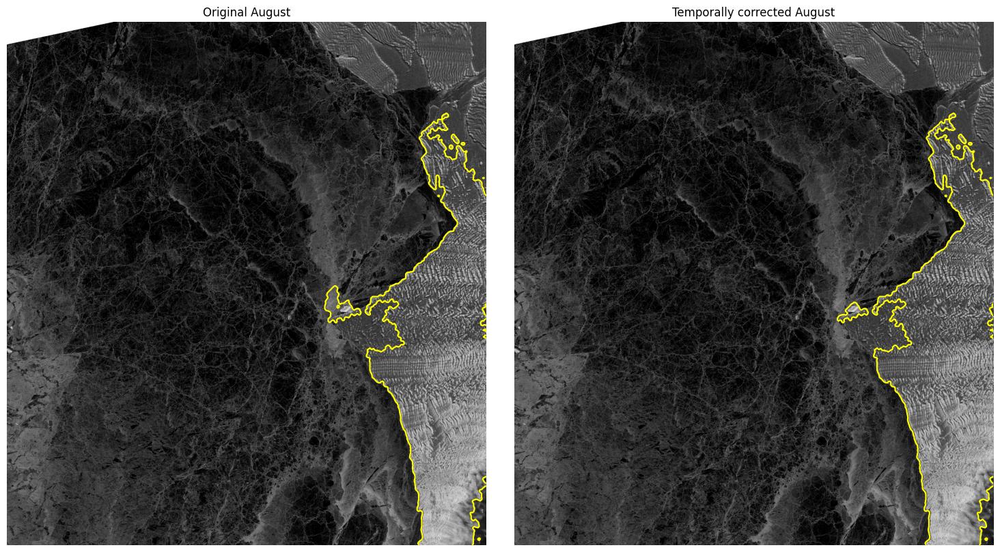

In [47]:
august_corrected = august.copy()

august_corrected[large_anomalies] = june[large_anomalies]

fig, axes = plt.subplots(1, 2, figsize=(15, 8))

for ax, mask, title in zip(
    axes,
    [august, august_corrected],
    ["Original August", "Temporally corrected August"]
):
    ax.imshow(middle_db, cmap="gray", vmin=-25, vmax=5)

    ax.contour(
        mask.astype(float),
        levels=[0.5],
        colors="yellow",
        linewidths=1.5
    )

    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

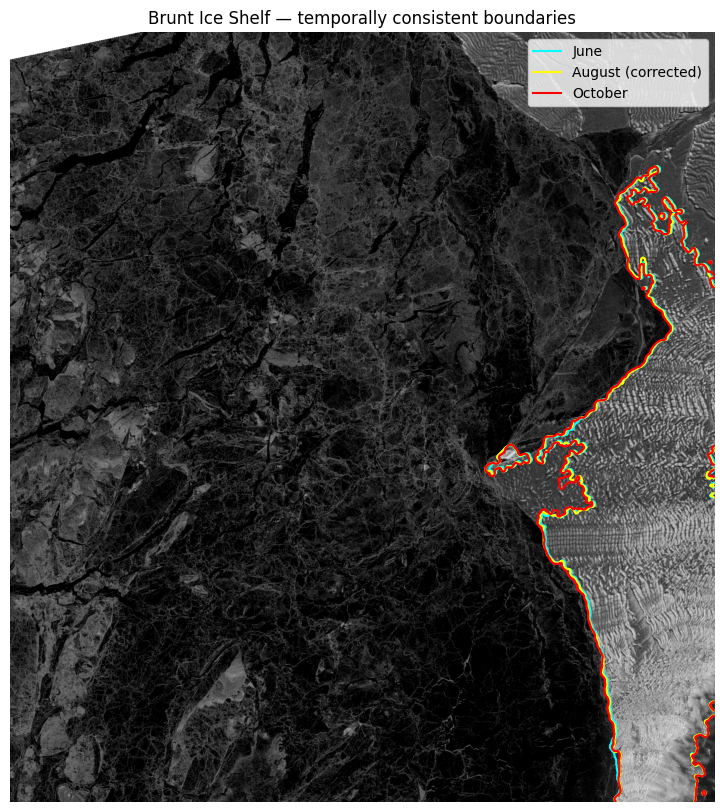

In [48]:
plt.figure(figsize=(11, 10))

plt.imshow(after_db, cmap="gray", vmin=-25, vmax=5)

for mask, color, name in zip(
    [june, august_corrected, october],
    ["cyan", "yellow", "red"],
    ["June", "August (corrected)", "October"]
):
    plt.contour(
        mask.astype(float),
        levels=[0.5],
        colors=color,
        linewidths=1.5
    )

    plt.plot([], [], color=color, label=name)

plt.legend()
plt.title("Brunt Ice Shelf — temporally consistent boundaries")
plt.axis("off")
plt.show()

In [49]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader

device = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Device:", device)

Device: mps


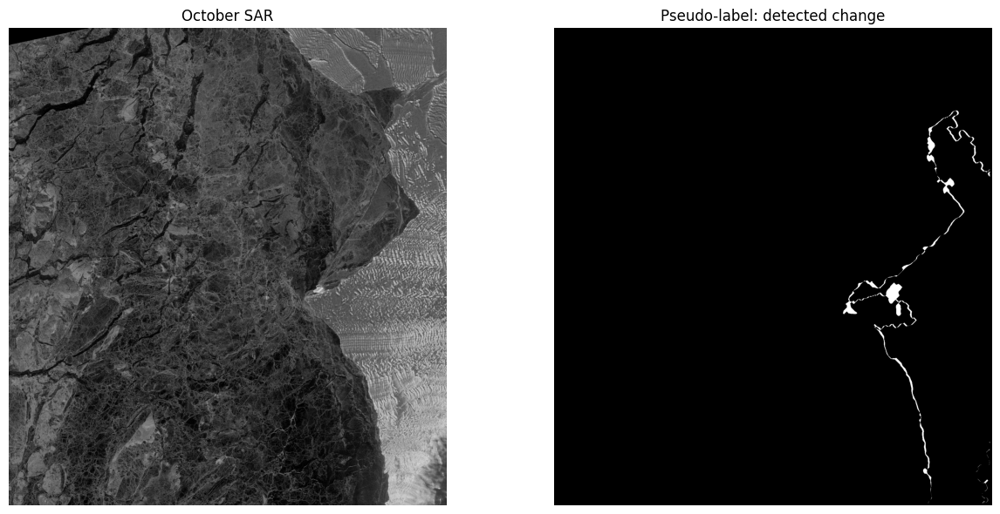

In [50]:
# Both masks describe the same radar class
pseudo_change = (
    mask_june.astype(bool) ^
    mask_october.astype(bool)
)

valid_pair = valid_before & valid_after

pseudo_change &= valid_pair

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

axes[0].imshow(after_input, cmap="gray")
axes[0].set_title("October SAR")

axes[1].imshow(pseudo_change, cmap="gray")
axes[1].set_title("Pseudo-label: detected change")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [51]:
positive = pseudo_change[valid_pair].sum()
negative = valid_pair.sum() - positive

pos_weight = min(float(negative / max(positive, 1)), 10.0)

print("Positive class weight:", pos_weight)

def combined_loss(logits, targets, valid):
    bce = F.binary_cross_entropy_with_logits(
        logits,
        targets,
        pos_weight=torch.tensor(
            pos_weight,
            device=logits.device
        ),
        reduction="none"
    )

    bce = (bce * valid).sum() / valid.sum().clamp_min(1)

    probs = torch.sigmoid(logits) * valid
    targets = targets * valid

    intersection = (probs * targets).sum(dim=(1, 2, 3))
    denominator = (
        probs.sum(dim=(1, 2, 3)) +
        targets.sum(dim=(1, 2, 3))
    )

    dice = 1 - (
        (2 * intersection + 1) /
        (denominator + 1)
    ).mean()

    return bce + dice

Positive class weight: 10.0


In [52]:
# def combined_loss(logits, targets, valid):
#     bce = F.binary_cross_entropy_with_logits(
#         logits,
#         targets,
#         reduction="none"
#     )

#     bce = (bce * valid).sum() / valid.sum().clamp_min(1)

#     probs = torch.sigmoid(logits) * valid
#     targets = targets * valid

#     intersection = (probs * targets).sum(dim=(1, 2, 3))
#     denominator = (
#         probs.sum(dim=(1, 2, 3)) +
#         targets.sum(dim=(1, 2, 3))
#     )

#     dice_loss = 1 - (
#         (2 * intersection + 1) /
#         (denominator + 1)
#     ).mean()

#     return bce + dice_loss

In [53]:
class SARChangeDataset(Dataset):
    def __init__(self, before, after, mask, valid, size=256, stride=128):
        self.samples = []

        h, w = before.shape

        for y in range(0, h - size + 1, stride):
            for x in range(0, w - size + 1, stride):
                v = valid[y:y+size, x:x+size]

                if v.mean() < 0.9:
                    continue

                a = before[y:y+size, x:x+size]
                b = after[y:y+size, x:x+size]
                m = mask[y:y+size, x:x+size]

                self.samples.append((
                    # np.stack([a, b]).astype(np.float32),
                    np.stack([a, b, np.abs(b - a)]).astype(np.float32),
                    m[None].astype(np.float32),
                    v[None].astype(np.float32)
                ))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        x, y, valid = self.samples[idx]
        return torch.from_numpy(x), torch.from_numpy(y), torch.from_numpy(valid)


dataset = SARChangeDataset(
    before_input,
    after_input,
    pseudo_change,
    valid_pair
)

loader = DataLoader(dataset, batch_size=4, shuffle=True)

print("Number of patches:", len(dataset))

Number of patches: 127


In [54]:
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.net(x)


class SmallUNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.enc1 = DoubleConv(3, 16)
        self.enc2 = DoubleConv(16, 32)
        self.enc3 = DoubleConv(32, 64)

        self.pool = nn.MaxPool2d(2)

        self.up2 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec2 = DoubleConv(64, 32)

        self.up1 = nn.ConvTranspose2d(32, 16, 2, stride=2)
        self.dec1 = DoubleConv(32, 16)

        self.output = nn.Conv2d(16, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))

        d2 = self.up2(e3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.output(d1)


model = SmallUNet().to(device)

print("Parameters:", sum(p.numel() for p in model.parameters()))

Parameters: 117041


In [55]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

positive = pseudo_change[valid_pair].sum()
negative = valid_pair.sum() - positive

pos_weight = min(float(negative / max(positive, 1)), 30.0)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(pos_weight, device=device),
    reduction="none"
)

epochs = 15
loss_history = []

for epoch in range(epochs):
    model.train()
    total_loss = 0

    for x, y, v in loader:
        x = x.to(device)
        y = y.to(device)
        v = v.to(device)

        optimizer.zero_grad()

        logits = model(x)

        # loss_map = criterion(logits, y)
        # loss = (loss_map * v).sum() / v.sum().clamp_min(1)
        loss = combined_loss(logits, y, v)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(loader)
    loss_history.append(avg_loss)

    print(f"Epoch {epoch+1:02d}/{epochs} | Loss: {avg_loss:.4f}")

Epoch 01/15 | Loss: 1.6414
Epoch 02/15 | Loss: 1.5710
Epoch 03/15 | Loss: 1.5399
Epoch 04/15 | Loss: 1.5607
Epoch 05/15 | Loss: 1.5610
Epoch 06/15 | Loss: 1.5681
Epoch 07/15 | Loss: 1.5436
Epoch 08/15 | Loss: 1.5265
Epoch 09/15 | Loss: 1.5369
Epoch 10/15 | Loss: 1.5257
Epoch 11/15 | Loss: 1.5231
Epoch 12/15 | Loss: 1.5383
Epoch 13/15 | Loss: 1.5207
Epoch 14/15 | Loss: 1.5225
Epoch 15/15 | Loss: 1.5177


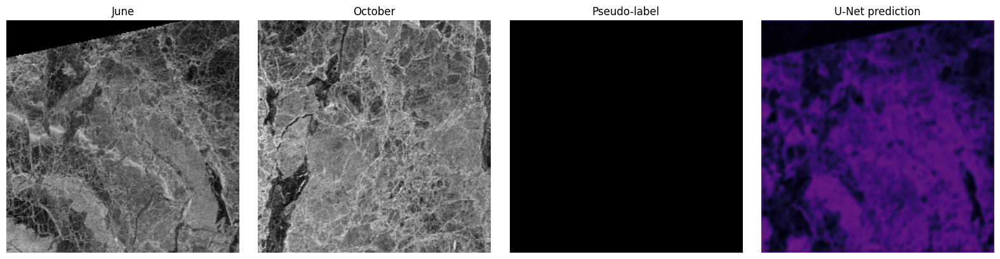

In [56]:
model.eval()

x, target, valid_patch = dataset[0]

with torch.no_grad():
    logits = model(x.unsqueeze(0).to(device))
    prediction = torch.sigmoid(logits)[0, 0].cpu().numpy()

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(x[0], cmap="gray")
axes[0].set_title("June")

axes[1].imshow(x[1], cmap="gray")
axes[1].set_title("October")

axes[2].imshow(target[0], cmap="gray")
axes[2].set_title("Pseudo-label")

axes[3].imshow(prediction, cmap="magma", vmin=0, vmax=1)
axes[3].set_title("U-Net prediction")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [57]:
# Find patches containing pseudo-labeled changes
change_counts = [
    dataset[i][1].sum().item()
    for i in range(len(dataset))
]

print("Total patches:", len(dataset))
print("Patches with changes:", sum(c > 0 for c in change_counts))
print("Maximum changed pixels:", max(change_counts))

best_idx = int(np.argmax(change_counts))
print("Patch with most changes:", best_idx)

Total patches: 127
Patches with changes: 31
Maximum changed pixels: 6878.0
Patch with most changes: 80


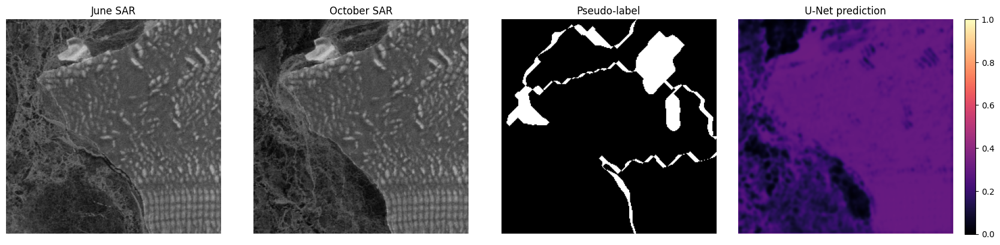

In [58]:
model.eval()

x, target, valid_patch = dataset[best_idx]

with torch.no_grad():
    logits = model(x.unsqueeze(0).to(device))
    prediction = torch.sigmoid(logits)[0, 0].cpu().numpy()

fig, axes = plt.subplots(1, 4, figsize=(17, 4))

axes[0].imshow(x[0], cmap="gray", vmin=0, vmax=1)
axes[0].set_title("June SAR")

axes[1].imshow(x[1], cmap="gray", vmin=0, vmax=1)
axes[1].set_title("October SAR")

axes[2].imshow(target[0], cmap="gray", vmin=0, vmax=1)
axes[2].set_title("Pseudo-label")

im = axes[3].imshow(prediction, cmap="magma", vmin=0, vmax=1)
axes[3].set_title("U-Net prediction")

fig.colorbar(im, ax=axes[3], fraction=0.046)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [59]:
pred_binary = (prediction > 0.5) & valid_patch[0].numpy().astype(bool)
true_binary = target[0].numpy().astype(bool) & valid_patch[0].numpy().astype(bool)

intersection = np.logical_and(pred_binary, true_binary).sum()
union = np.logical_or(pred_binary, true_binary).sum()

dice = 2 * intersection / max(pred_binary.sum() + true_binary.sum(), 1)
iou = intersection / max(union, 1)

print(f"Dice: {dice:.4f}")
print(f"IoU: {iou:.4f}")
print(f"Predicted change pixels: {pred_binary.sum()}")
print(f"Pseudo-label change pixels: {true_binary.sum()}")

Dice: 0.0000
IoU: 0.0000
Predicted change pixels: 0
Pseudo-label change pixels: 6878


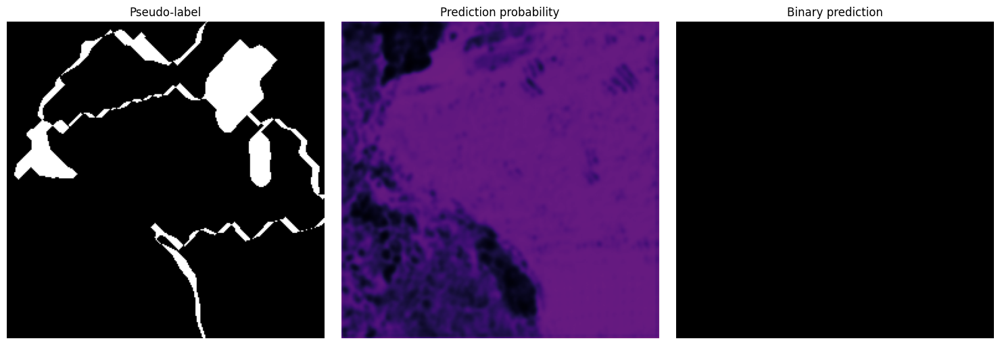

In [60]:
model.eval()

x, target, valid_patch = dataset[best_idx]

with torch.no_grad():
    prediction = torch.sigmoid(
        model(x.unsqueeze(0).to(device))
    )[0, 0].cpu().numpy()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(target[0], cmap="gray")
axes[0].set_title("Pseudo-label")

axes[1].imshow(prediction, cmap="magma", vmin=0, vmax=1)
axes[1].set_title("Prediction probability")

axes[2].imshow(prediction > 0.5, cmap="gray")
axes[2].set_title("Binary prediction")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [61]:
print("Prediction min:", prediction.min())
print("Prediction max:", prediction.max())
print("Prediction mean:", prediction.mean())

print("Pseudo-label positive ratio:", target.float().mean().item())

print("Predicted > 0.1:", (prediction > 0.1).mean())
print("Predicted > 0.3:", (prediction > 0.3).mean())
print("Predicted > 0.5:", (prediction > 0.5).mean())

Prediction min: 0.009999678
Prediction max: 0.3488128
Prediction mean: 0.24023072
Pseudo-label positive ratio: 0.104949951171875
Predicted > 0.1: 0.9241180419921875
Predicted > 0.3: 0.2177581787109375
Predicted > 0.5: 0.0
